In [4]:
import os
import tensorflow as tf

print("Current folder:", os.getcwd())
print("Model file exists:", os.path.exists("tomato_model_v4.keras"))
print("Files:", os.listdir())

Current folder: c:\Users\vijay\Downloads\tomato_model_project
Model file exists: True
Files: ['app.py', 'test_folder', 'Tomato-Disease-Prediction.ipynb', 'tomato_model_v4.keras']


In [5]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from PIL import Image
import matplotlib.pyplot as plt

print("All libraries imported !")

All libraries imported !


In [6]:
import os
from tensorflow.keras.models import load_model

possible_paths = [
    r"C:\Users\vijay\Downloads\tomato_model_project\tomato_model_v4.keras",
    r"C:\Users\vijay\Downloads\tomato_model_v4.keras",
    r"C:\Users\vijay\Downloads\tomato_model_project\tomato_model_SUPER.h5",
    r"C:\Users\vijay\Downloads\tomato_model_project\tomato_model.h5"
]

model_path = None

for path in possible_paths:
    if os.path.exists(path):
        model_path = path
        break

if model_path:
    model = load_model(model_path, compile=False)
    print("Model loaded successfully!")
    print("Model path:", model_path)
    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)
else:
    print("Model file not found!")
    print("Please check where your model file is saved.")

Model loaded successfully!
Model path: C:\Users\vijay\Downloads\tomato_model_project\tomato_model_v4.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 10)


## Loading the Trained Tomato Disease Prediction Model

In [7]:
class_names = [
    'Bacterial_spot',
    'Early_blight',
    'Late_blight',
    'Leaf_Mold',
    'Septoria_leaf_spot',
    'Spider_mites',
    'Target_Spot',
    'YellowLeaf_Curl_Virus',
    'mosaic_virus',
    'healthy'
]
print(class_names)


['Bacterial_spot', 'Early_blight', 'Late_blight', 'Leaf_Mold', 'Septoria_leaf_spot', 'Spider_mites', 'Target_Spot', 'YellowLeaf_Curl_Virus', 'mosaic_virus', 'healthy']


##  Defining Tomato Disease Class Names

In [8]:
import numpy as np
import tensorflow as tf
import os

print(f"TensorFlow Version: {tf.__version__}")

MODEL_PATH = r"C:\Users\vijay\Downloads\tomato_model_project\tomato_model_v4.keras"
VAL_DIR = r"C:\Users\vijay\Downloads\Tomato_leaf_Detection\tomato\val"

print(f"Checking MODEL_PATH: {MODEL_PATH}")
print(f"Model exists: {os.path.exists(MODEL_PATH)}")

if os.path.exists(MODEL_PATH):
    print(f"Is file: {os.path.isfile(MODEL_PATH)}")
    print(f"File size: {os.path.getsize(MODEL_PATH) / (1024*1024):.2f} MB")
    
    try:
        model = tf.keras.models.load_model(MODEL_PATH, compile=False)
        print("Model loaded successfully!")
    except:
        print("First method failed, trying with safe_mode=False...")
        model = tf.keras.models.load_model(MODEL_PATH, compile=False, safe_mode=False)
        print("Model loaded with safe_mode=False!")

    size = model.input_shape[1]
    print(f"Model input size: {size}")
    
    print(f"Checking VAL_DIR: {VAL_DIR}")
    print(f"Val exists: {os.path.exists(VAL_DIR)}")
    print(f"Files in val: {os.listdir(VAL_DIR)}")

    ds = tf.keras.utils.image_dataset_from_directory(
        VAL_DIR, image_size=(size, size), batch_size=32, shuffle=False
    )
    print(f"Class order: {ds.class_names}")

    y_true = np.concatenate([y.numpy() for _, y in ds])

    for name, scale in [("without /255", 1.0), ("with /255", 1/255.0)]:
        preds = model.predict(ds.map(lambda x, y: (x * scale, y)), verbose=0)
        acc = (preds.argmax(axis=1) == y_true).mean() * 100
        print(f"{name}: accuracy = {acc:.1f}%")
        preds = model.predict(ds.map(lambda x, y: (x * scale, y)), verbose=0)
        acc = (preds.argmax(axis=1) == y_true).mean() * 100
        print(f"{name}: accuracy = {acc:.1f}%")

TensorFlow Version: 2.21.0
Checking MODEL_PATH: C:\Users\vijay\Downloads\tomato_model_project\tomato_model_v4.keras
Model exists: True
Is file: True
File size: 25.17 MB
Model loaded successfully!
Model input size: 224
Checking VAL_DIR: C:\Users\vijay\Downloads\Tomato_leaf_Detection\tomato\val
Val exists: True
Files in val: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_mosaic_virus', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
Found 1000 files belonging to 10 classes.
Class order: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
without /255: accuracy = 9

In [9]:
import os

home = os.path.expanduser("~")

for folder in ["Downloads", "Desktop", "Documents"]:
    for root, dirs, files in os.walk(os.path.join(home, folder)):
        if any("healthy" in d.lower() for d in dirs):
            print(root)
            print(sorted(dirs))
            print()

C:\Users\vijay\Downloads\Tomato_leaf_Detection\tomato\train
['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']

C:\Users\vijay\Downloads\Tomato_leaf_Detection\tomato\val
['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']



## **Finding the Tomato Dataset Folder**

In [10]:
import numpy as np
import tensorflow as tf

MODEL_PATH = "tomato_model_v4.keras"
VAL_DIR = r"C:\Users\vijay\Downloads\Tomato_leaf_Detection\tomato\val"

model = tf.keras.models.load_model(MODEL_PATH, compile=False)
size = model.input_shape[1]

ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=(size, size), batch_size=32, shuffle=False
)

print("Class order:")
for i, n in enumerate(ds.class_names):
    print(i, n)

y_true = np.concatenate([y.numpy() for _, y in ds])

for name, scale in [("without /255", 1.0), ("with /255", 1 / 255.0)]:
    preds = model.predict(ds.map(lambda x, y: (x * scale, y)), verbose=0)
    acc = (preds.argmax(axis=1) == y_true).mean() * 100
    print(f"{name}: accuracy = {acc:.1f}%")

Found 1000 files belonging to 10 classes.
Class order:
0 Tomato___Bacterial_spot
1 Tomato___Early_blight
2 Tomato___Late_blight
3 Tomato___Leaf_Mold
4 Tomato___Septoria_leaf_spot
5 Tomato___Spider_mites Two-spotted_spider_mite
6 Tomato___Target_Spot
7 Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 Tomato___Tomato_mosaic_virus
9 Tomato___healthy
without /255: accuracy = 94.8%
with /255: accuracy = 10.0%


## **Evaluating the Model on Validation Images**


In [11]:
import os
import glob
import numpy as np
import tensorflow as tf

home = os.path.expanduser("~")
found = glob.glob(os.path.join(home, "Downloads", "**", "*.keras"), recursive=True)
MODEL_PATH = max(found, key=os.path.getmtime)
VAL_DIR = r"C:\Users\vijay\Downloads\Tomato_leaf_Detection\tomato\val"
print("Model:", MODEL_PATH)

model = tf.keras.models.load_model(MODEL_PATH, compile=False)
size = model.input_shape[1]

ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=(size, size), batch_size=32, shuffle=False
)

y_true = np.concatenate([y.numpy() for _, y in ds])
y_pred = model.predict(ds, verbose=0).argmax(axis=1)

print(f"\nValidation accuracy: {(y_pred == y_true).mean() * 100:.1f}%\n")
for i, n in enumerate(ds.class_names):
    m = y_true == i
    print(f"{n:<48} {(y_pred[m] == i).mean() * 100:5.1f}%")

Model: C:\Users\vijay\Downloads\tomato_model_project\tomato_model_v4.keras
Found 1000 files belonging to 10 classes.

Validation accuracy: 94.8%

Tomato___Bacterial_spot                           99.0%
Tomato___Early_blight                             83.0%
Tomato___Late_blight                              96.0%
Tomato___Leaf_Mold                                98.0%
Tomato___Septoria_leaf_spot                       96.0%
Tomato___Spider_mites Two-spotted_spider_mite     93.0%
Tomato___Target_Spot                              89.0%
Tomato___Tomato_Yellow_Leaf_Curl_Virus            95.0%
Tomato___Tomato_mosaic_virus                      99.0%
Tomato___healthy                                 100.0%


##  **Calculating Overall and Class-wise Accuracy**

In [12]:
import tensorflow as tf

MODEL_PATH = r"C:\Users\vijay\Downloads\tomato_model_project\tomato_model_v4.keras"

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nModel layers:")
for layer in model.layers:
    print(layer.name, layer.__class__.__name__, layer.get_config().get("scale", ""))

Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 10)

Model layers:
input_layer_1 InputLayer 
sequential Sequential 
mobilenetv2_1.00_224 Functional 
global_average_pooling2d GlobalAveragePooling2D 
dropout Dropout 
dense Dense 


## **Predicting Tomato Diseases from Test Images**



Model : C:\Users\vijay\Downloads\tomato_model_project\tomato_model_v4.keras
Images: C:\Users\vijay\Downloads\tomato_model_project\test_folder
Found 14 images


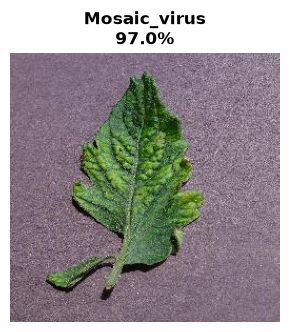

Image: adb470b2-bae7-4386-bbc2-cda168dd69e2___PSU_CG 2315.JPG -> Mosaic_virus (97.03%)


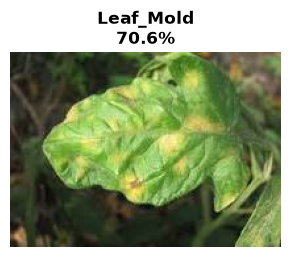

Image: download.jpg -> Leaf_Mold (70.58%)


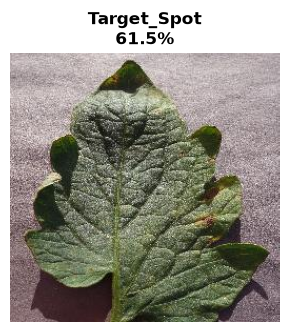

Image: e1b0584e-fa68-446c-85e1-1658252585db___Com.G_TgS_FL 1125.JPG -> Target_Spot (61.52%)


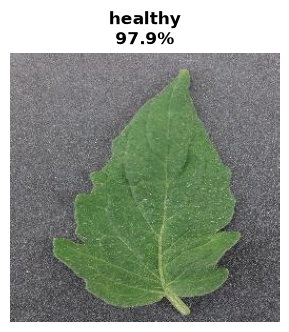

Image: edbb09c6-f6e6-4ce4-ac38-e4fa0b96f4c0___GH_HL Leaf 251.JPG -> healthy (97.89%)


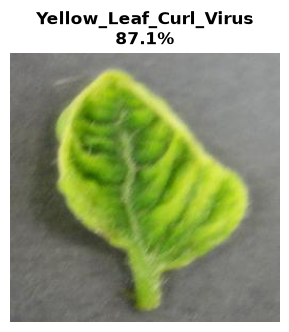

Image: f8dfef7f-9548-4e77-b9d6-69854ed088ce___UF.GRC_YLCV_Lab 01856.JPG -> Yellow_Leaf_Curl_Virus (87.15%)


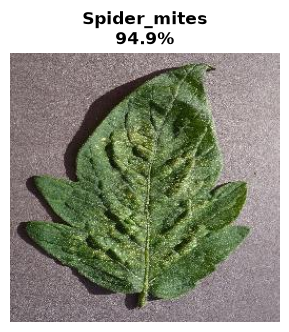

Image: fab1a3c8-938d-474e-beb0-d34a68afdd17___Com.G_SpM_FL 1718.JPG -> Spider_mites (94.95%)


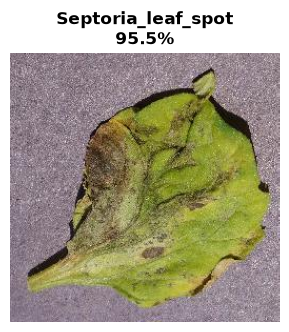

Image: fb6bea39-f361-457c-b73e-fe3b2dbe6259___Matt.S_CG 2786.JPG -> Septoria_leaf_spot (95.49%)


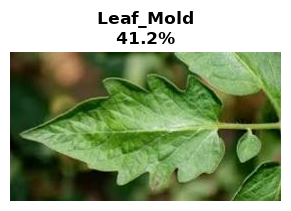

Image: final test.jpg -> Leaf_Mold (41.25%)


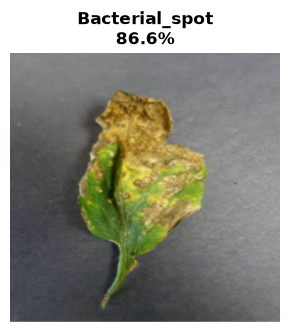

Image: images.jpg -> Bacterial_spot (86.61%)


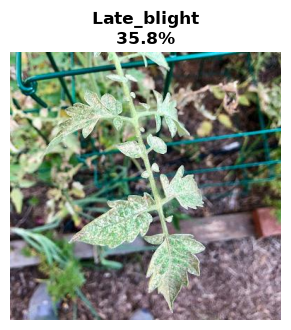

Image: spiderr.jpg -> Late_blight (35.83%)


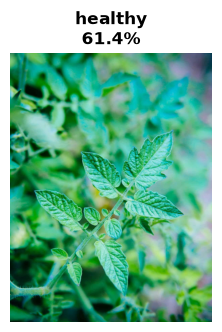

Image: test 25.jpg -> healthy (61.38%)


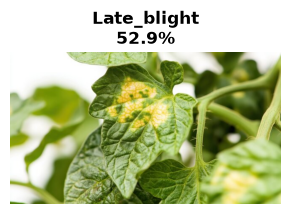

Image: test again.jpg -> Late_blight (52.86%)


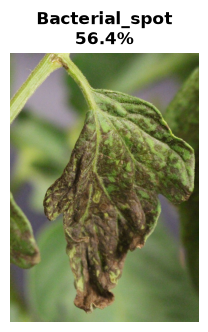

Image: tomato-disease-11-TSWV.jpg -> Bacterial_spot (56.43%)


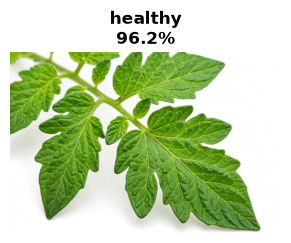

Image: WhatsApp Image 2026-10-17 at 4.58.20 PM (1) - Copy.jpg -> healthy (96.15%)


In [14]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps


IMAGE_DIR = r"C:\Users\vijay\Downloads\tomato_model_project\test_folder"


home = os.path.expanduser("~")
found = glob.glob(os.path.join(home, "Downloads", "**", "*.keras"), recursive=True)
MODEL_PATH = max(found, key=os.path.getmtime) if found else None

print("Model :", MODEL_PATH)
print("Images:", IMAGE_DIR)

assert MODEL_PATH, "No .keras model file found in Downloads"
assert os.path.isdir(IMAGE_DIR), "Images folder not found"


CLASS_NAMES = [
    "Bacterial_spot",
    "Early_blight",
    "Late_blight",
    "Leaf_Mold",
    "Septoria_leaf_spot",
    "Spider_mites",
    "Target_Spot",
    "Yellow_Leaf_Curl_Virus",
    "Mosaic_virus",
    "healthy",
]


model = tf.keras.models.load_model(MODEL_PATH, compile=False)
size = model.input_shape[1]

files = [f for f in os.listdir(IMAGE_DIR)
         if f.lower().endswith((".jpg", ".jpeg", ".png"))]
print("Found", len(files), "images")


for f in files:
    img = ImageOps.exif_transpose(Image.open(os.path.join(IMAGE_DIR, f))).convert("RGB")

    arr = np.asarray(img.resize((size, size)), dtype=np.float32)
    arr = np.expand_dims(arr, axis=0)

    scores = model.predict(arr, verbose=0)[0]
    if not np.isclose(scores.sum(), 1.0, atol=1e-3):
        scores = tf.nn.softmax(scores).numpy()

    order = np.argsort(scores)[::-1]

    
    top_class = CLASS_NAMES[order[0]]
    top_conf = scores[order[0]] * 100
    
    plt.figure(figsize=(3.5, 3.5))
    plt.imshow(img)
    plt.title(f"{top_class}\n{top_conf:.1f}%", fontsize=12, fontweight='bold')
    plt.axis('off')
    plt.show()
    
    print(f"Image: {f} -> {top_class} ({top_conf:.2f}%)")